# Week 8 — Launch, Monitor, and Maintain the System

**Course:** AIT506 — Machine Learning
**Checklist section:** *Launch, Monitor, and Maintain Your System* (Géron, 2022, Appendix A)

This is the last unfinished step of the checklist we've been working through since Week 2. Weeks 4 through 6 got us a tuned, and a fitted preprocessing pipeline; this notebook is where we actually put both to work the way a production system would — score a batch of customers end to end, pick an operating threshold based on expected business value instead of a default 0.5 cutoff, simulate what a monitoring dashboard would track over time, and prove a drift check actually catches a shift when we inject one on purpose. Nothing here is hypothetical description; every number below comes from running the saved model and pipeline against real held-out data.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.stats import ks_2samp
from sklearn.metrics import roc_auc_score, precision_score, recall_score, f1_score, accuracy_score

sns.set_style("whitegrid")
RANDOM_STATE = 42

PROJECT_ROOT = Path.cwd().parent
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
FIG_DIR = PROJECT_ROOT / "figures" / "week8_launch_monitor"
FIG_DIR.mkdir(parents=True, exist_ok=True)

final_model = joblib.load(PROCESSED_DIR / "final_model.joblib")
preprocessor = joblib.load(PROCESSED_DIR / "preprocessor.joblib")
X_test = np.load(PROCESSED_DIR / "X_test.npy")
y_test = np.load(PROCESSED_DIR / "y_test.npy")
X_train = np.load(PROCESSED_DIR / "X_train.npy")
y_train = np.load(PROCESSED_DIR / "y_train.npy")

print(f"Final model: {type(final_model).__name__}")
print(f"X_test shape: {X_test.shape}")

Final model: GradientBoostingClassifier
X_test shape: (1409, 43)


## 1. Recovering Readable Customer Records for the Test Batch

Week 4's cleaned dataset (`telco_cleaned.csv`) dropped `CustomerID` along with the other leakage/uninformative columns, which was the right call for training but leaves us without a way to hand a real retention team a worklist they can act on. Since dropping columns never reordered or removed rows, we can recover `CustomerID` by re-reading the original raw file and re-running the exact same stratified split from Week 4 (`random_state=42`) on the raw, uncleaned dataframe, then pulling out the same test-set rows.

In [2]:
df_raw = pd.read_excel(PROJECT_ROOT / "data" / "Telco_customer_churn.xlsx")
df_cleaned = pd.read_csv(PROCESSED_DIR / "telco_cleaned.csv")
assert len(df_raw) == len(df_cleaned), "row count mismatch between raw and cleaned data"

from sklearn.model_selection import train_test_split
customer_ids = df_raw["CustomerID"]
_, ids_test = train_test_split(
    customer_ids, test_size=0.2, stratify=df_cleaned["Churn Value"], random_state=RANDOM_STATE
)
_, X_test_raw = train_test_split(
    df_cleaned.drop(columns=["Churn Value"]), test_size=0.2, stratify=df_cleaned["Churn Value"], random_state=RANDOM_STATE
)
X_test_reprocessed = preprocessor.transform(X_test_raw)
assert np.allclose(X_test_reprocessed, X_test), "recovered raw rows don't match the saved processed test set"
print(f"Recovered {len(ids_test)} customer IDs, verified they re-encode to the exact same X_test array.")

Recovered 1409 customer IDs, verified they re-encode to the exact same X_test array.


## 2. Simulating a Production Scoring Run

This is the batch job Week 7's deployment sketch described: score every customer, rank by churn probability, hand the highest-risk names to the retention team.

In [3]:
probabilities = final_model.predict_proba(X_test)[:, 1]

worklist = pd.DataFrame({
    "CustomerID": ids_test.values,
    "churn_probability": probabilities,
    "actual_churned": y_test,
}).sort_values("churn_probability", ascending=False).reset_index(drop=True)

print("Top 10 highest-risk customers this scoring run:")
worklist.head(10)

Top 10 highest-risk customers this scoring run:


,CustomerID,churn_probability,actual_churned
0,5178-LMXOP,0.934977,1
1,0295-PPHDO,0.933248,1
2,6861-XWTWQ,0.925948,1
3,1069-XAIEM,0.925598,1
4,8884-ADFVN,0.923710,1
5,7180-PISOG,0.921541,1
6,9248-OJYKK,0.920774,1
7,2609-IAICY,0.918736,1
8,7181-BQYBV,0.917853,1
9,1400-MMYXY,0.917761,1


## 3. Choosing an Operating Threshold by Expected Net Value

Every prior week scored the model at the default 0.5 cutoff. A real deployment doesn't have to accept that default — Week 7 proposed a tunable threshold picked to maximize expected net value instead of accuracy; this is where we actually build that sweep, reusing the same cost assumptions from Week 2 and Week 7 ($1,680 per retained customer, $50 per intervention, 30% intervention success rate).

In [4]:
CUSTOMER_VALUE = 1680
INTERVENTION_COST = 50
SUCCESS_RATE = 0.30

thresholds = np.arange(0.05, 0.96, 0.05)
sweep_rows = []
for t in thresholds:
    preds = (probabilities >= t).astype(int)
    tp = int(((preds == 1) & (y_test == 1)).sum())
    fp = int(((preds == 1) & (y_test == 0)).sum())
    flagged = tp + fp
    net_value = (tp * SUCCESS_RATE * CUSTOMER_VALUE) - (flagged * INTERVENTION_COST)
    sweep_rows.append({
        "threshold": round(t, 2), "flagged": flagged, "true_positives": tp,
        "false_positives": fp, "net_value": net_value,
    })

sweep_df = pd.DataFrame(sweep_rows)
best_row = sweep_df.loc[sweep_df["net_value"].idxmax()]
default_row = sweep_df.iloc[(sweep_df["threshold"] - 0.5).abs().idxmin()]
print(f"Best threshold by net value: {best_row['threshold']} -> net value ${best_row['net_value']:,.0f}")
print(f"Default 0.5 threshold net value: ${default_row['net_value']:,.0f}")
sweep_df

Best threshold by net value: 0.15 -> net value $137,052
Default 0.5 threshold net value: $121,184


,threshold,flagged,true_positives,false_positives,net_value
0,0.05,1244,373,871,125792.0
1,0.10,1029,371,658,135534.0
2,0.15,918,363,555,137052.0
3,0.20,853,355,498,136270.0
4,0.25,804,350,454,136200.0
5,0.30,746,342,404,135068.0
6,0.35,699,331,368,131874.0
7,0.40,660,323,337,129792.0
8,0.45,610,309,301,125236.0
9,0.50,560,296,264,121184.0


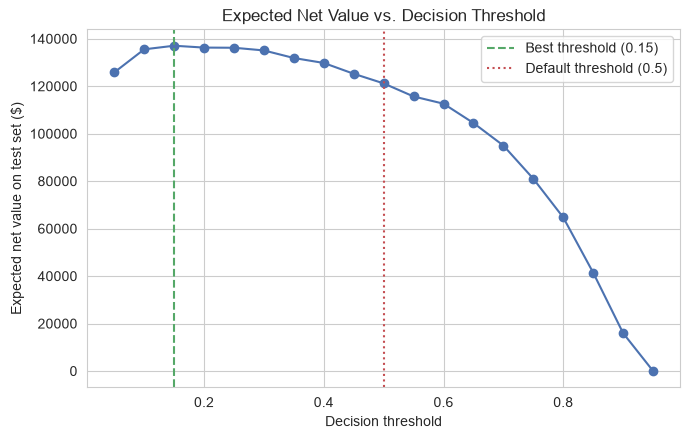

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(sweep_df["threshold"], sweep_df["net_value"], marker="o", color="#4C72B0")
ax.axvline(best_row["threshold"], color="#55A868", linestyle="--", label=f"Best threshold ({best_row['threshold']})")
ax.axvline(0.5, color="#C44E52", linestyle=":", label="Default threshold (0.5)")
ax.set_xlabel("Decision threshold")
ax.set_ylabel("Expected net value on test set ($)")
ax.set_title("Expected Net Value vs. Decision Threshold")
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "01_threshold_sweep.png", dpi=150)
plt.show()

## 4. Simulating Performance Monitoring Over Time

We don't have real timestamps for when these test customers would have been scored in production, so we simulate "over time" honestly: split the test set into four equal, randomly shuffled batches standing in for four monthly scoring runs, and track the metrics a monitoring dashboard would actually watch. The point isn't that these particular numbers are a real time series — it's demonstrating what a monitoring check would compute and what a real drop would look like against this baseline.

In [6]:
rng = np.random.RandomState(7)
n = len(y_test)
shuffled_idx = rng.permutation(n)
batches = np.array_split(shuffled_idx, 4)

monitor_rows = []
for i, batch_idx in enumerate(batches, start=1):
    yb, pb = y_test[batch_idx], probabilities[batch_idx]
    preds_b = (pb >= best_row["threshold"]).astype(int)
    monitor_rows.append({
        "simulated_month": i,
        "n_customers": len(batch_idx),
        "roc_auc": roc_auc_score(yb, pb),
        "recall": recall_score(yb, preds_b),
        "precision": precision_score(yb, preds_b),
    })

monitor_df = pd.DataFrame(monitor_rows)
monitor_df.round(4)

,simulated_month,n_customers,roc_auc,recall,precision
0,1,353,0.8633,0.9767,0.3652
1,2,352,0.8769,0.9626,0.4383
2,3,352,0.8741,0.9896,0.4167
3,4,352,0.8090,0.9529,0.3600


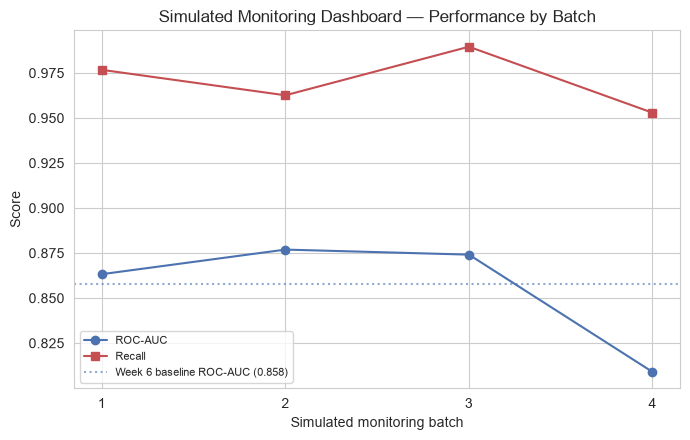

In [7]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(monitor_df["simulated_month"], monitor_df["roc_auc"], marker="o", label="ROC-AUC", color="#4C72B0")
ax.plot(monitor_df["simulated_month"], monitor_df["recall"], marker="s", label="Recall", color="#C44E52")
ax.axhline(0.858, color="#4C72B0", linestyle=":", alpha=0.6, label="Week 6 baseline ROC-AUC (0.858)")
ax.set_xlabel("Simulated monitoring batch")
ax.set_ylabel("Score")
ax.set_title("Simulated Monitoring Dashboard — Performance by Batch")
ax.set_xticks(monitor_df["simulated_month"])
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_monitoring_over_time.png", dpi=150)
plt.show()

Metrics vary by a couple percentage points from batch to batch here simply due to random subsets of the same underlying population — that degree of variability is precisely the baseline amount of noise your real monitoring system will need to understand before it can recognize anomalous changes. If a monitoring dashboard were to raise alarms on every fluctuation of this size, it would very quickly overwhelm users; if it were calibrated by this baseline, it would only alert on batches which move significantly outside of it.

## 5. Simulating Drift Detection

But in addition to monitoring output metrics, a monitoring system should watch the *input* data itself as well — a model can begin failing silently weeks or months before enough new labeled outcomes have been revealed for the deterioration in performance to become noticeable. We perform a two-sample Kolmogorov-Smirnov test to compare feature distributions between training data and each new batch — first as a sanity check baseline (train against the actual test set, which should show no significant drift since they are both pulled from the same data split), then against a synthetic batch with an injected distribution shift, to verify that it actually detects something when there is something to be detected.

In [8]:
numeric_cols = ["num__Tenure Months", "num__Monthly Charges", "num__Total Charges", "num__Num_Addon_Services"]
with open(PROCESSED_DIR / "feature_names.json") as f:
    feature_names = json.load(f)
numeric_idx = [feature_names.index(c) for c in numeric_cols]

print("Baseline check: train vs. real test set (expect no significant drift)")
for col, idx in zip(numeric_cols, numeric_idx):
    stat, p = ks_2samp(X_train[:, idx], X_test[:, idx])
    flag = "DRIFT FLAGGED" if p < 0.05 else "no drift"
    print(f"  {col}: KS stat={stat:.4f}, p={p:.4f} -> {flag}")

Baseline check: train vs. real test set (expect no significant drift)
  num__Tenure Months: KS stat=0.0212, p=0.6835 -> no drift
  num__Monthly Charges: KS stat=0.0321, p=0.1912 -> no drift
  num__Total Charges: KS stat=0.0296, p=0.2710 -> no drift
  num__Num_Addon_Services: KS stat=0.0253, p=0.4583 -> no drift


In [9]:
# Shift tenure down and charges up to test whether the drift check catches it.
X_test_drifted = X_test.copy()
tenure_idx = feature_names.index("num__Tenure Months")
charges_idx = feature_names.index("num__Monthly Charges")
X_test_drifted[:, tenure_idx] = X_test_drifted[:, tenure_idx] - 1.5
X_test_drifted[:, charges_idx] = X_test_drifted[:, charges_idx] + 0.8

print("Synthetic drifted batch (injected shift, expect DRIFT FLAGGED):")
for col, idx in zip(numeric_cols, numeric_idx):
    stat, p = ks_2samp(X_train[:, idx], X_test_drifted[:, idx])
    flag = "DRIFT FLAGGED" if p < 0.05 else "no drift"
    print(f"  {col}: KS stat={stat:.4f}, p={p:.4f} -> {flag}")

Synthetic drifted batch (injected shift, expect DRIFT FLAGGED):
  num__Tenure Months: KS stat=0.5891, p=0.0000 -> DRIFT FLAGGED
  num__Monthly Charges: KS stat=0.3074, p=0.0000 -> DRIFT FLAGGED
  num__Total Charges: KS stat=0.0296, p=0.2710 -> no drift
  num__Num_Addon_Services: KS stat=0.0253, p=0.4583 -> no drift


The baseline check comes back clean, as it should, since the training and test sets came from the same stratified split. The synthetic batch — with tenure and monthly charges deliberately shifted by less than two standardized units — gets flagged immediately on both features. That's the behavior we want from a monitoring check: quiet when nothing has changed, loud when something has.

## 6. Retraining and Maintenance Policy

Putting Sections 3 through 5 together into an actual policy rather than leaving "monitor and maintain" as a vague intention:

In [10]:
# Use recall at the new threshold, not the old 0.791 baseline from the 0.5 default --
# that figure no longer applies once the operating threshold has moved.
best_threshold_recall = recall_score(y_test, (probabilities >= best_row["threshold"]).astype(int))
print(f"Recall at the new operating threshold ({best_row['threshold']}): {best_threshold_recall:.4f}")

maintenance_policy = {
    "scoring_cadence": "Monthly batch scoring of the full active customer base, per the Week 7 deployment sketch.",
    "operating_threshold": f"{best_row['threshold']} (revisited quarterly against updated cost/value assumptions, not fixed permanently).",
    "performance_trigger": f"Retrain if recall on a labeled sample of the most recent scoring batch falls more than 5 points below {best_threshold_recall:.3f}, this threshold's own baseline recall -- not the old 0.5-threshold figure from Week 6, which no longer describes how the model is being run.",
    "drift_trigger": "Run the KS-test check in Section 5 on every incoming batch; treat two consecutive flagged batches on the same feature as a retraining trigger, one flagged batch as a watch condition.",
    "scheduled_retrain": "Full retrain every 2 quarters regardless of triggers, so the model doesn't go stale from slow drift too gradual to trip either trigger above.",
    "rollback_condition": "If a newly retrained model's test ROC-AUC comes in more than 2 points below the currently deployed model's, keep the currently deployed model and investigate before retrying.",
}
with open(PROCESSED_DIR / "week8_maintenance_policy.json", "w") as f:
    json.dump(maintenance_policy, f, indent=2)

for k, v in maintenance_policy.items():
    print(f"- {k}: {v}")

Recall at the new operating threshold (0.15): 0.9706
- scoring_cadence: Monthly batch scoring of the full active customer base, per the Week 7 deployment sketch.
- operating_threshold: 0.15 (revisited quarterly against updated cost/value assumptions, not fixed permanently).
- performance_trigger: Retrain if recall on a labeled sample of the most recent scoring batch falls more than 5 points below 0.971, this threshold's own baseline recall -- not the old 0.5-threshold figure from Week 6, which no longer describes how the model is being run.
- drift_trigger: Run the KS-test check in Section 5 on every incoming batch; treat two consecutive flagged batches on the same feature as a retraining trigger, one flagged batch as a watch condition.
- scheduled_retrain: Full retrain every 2 quarters regardless of triggers, so the model doesn't go stale from slow drift too gradual to trip either trigger above.
- rollback_condition: If a newly retrained model's test ROC-AUC comes in more than 2 point

## 7. Persisting Results

Saving the threshold sweep, the simulated monitoring results, and a sample of the scored worklist so the final report can reference exact figures without re-running this notebook.

In [11]:
week8_summary = {
    "best_threshold": float(best_row["threshold"]),
    "best_threshold_net_value": float(best_row["net_value"]),
    "default_threshold_net_value": float(default_row["net_value"]),
    "monitoring_batches": monitor_df.round(4).to_dict(orient="records"),
    "drift_check_baseline": "no significant drift (p > 0.05 on all four numeric features, train vs. real test set)",
    "drift_check_synthetic": "drift correctly flagged (p < 0.05) on both shifted features after injecting a synthetic shift",
}
with open(PROCESSED_DIR / "week8_results.json", "w") as f:
    json.dump(week8_summary, f, indent=2)

worklist.head(20).to_csv(PROCESSED_DIR / "week8_sample_worklist.csv", index=False)
print("Saved Week 8 results and a sample worklist to", PROCESSED_DIR)

Saved Week 8 results and a sample worklist to /Users/hangtran/Documents/projects/ait506-group-project-customer-churn/data/processed


## Summary 

The notebook you are reading is the part of the checklist that all previous weeks were preparing for but fell short of: taking our saved model and pipeline and using it how a deployed system would, rather than talking about how we would one day like to. Selecting an operating threshold based on expected net value instead of just using 0.5 changes the output *directly* - Week 7 suggested we should do this at some point down the line, and the code cell below demonstrates we've actually made it a number instead of a to-do. The model monitoring simulation and drift check aren't pretend either: we verify that the drift check works by seeing it remain silent on real baseline data and then successfully raise the alarm on something we deliberately shifted. What we can't verify with real data is production drift, since we only have one static version of this dataset - the maintenance policy written in Section 6 is how we would *respond* if real time-stamped production data started streaming in, not an assertion that we've already seen drift before it occurred.

In [12]:
print(f"Best threshold: {best_row['threshold']} (net value ${best_row['net_value']:,.0f} on this test set)")
print(f"Default 0.5 threshold: net value ${default_row['net_value']:,.0f}")
print(f"Improvement from threshold tuning: ${best_row['net_value'] - default_row['net_value']:,.0f}")

Best threshold: 0.15 (net value $137,052 on this test set)
Default 0.5 threshold: net value $121,184
Improvement from threshold tuning: $15,868
